In [22]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

### Section 4.2.1. Linear Regression

$$
\Pi = B_3 m_3^2 + B_3 k_{\text{diss}} m_2 m_3 + C_3 m_3^3 + k_c,
$$

where

- $B_3$ and $C_3$ are virial parameters to be determined,
- $m_2$ is the molality of NaCl in millimol/kg of solvent,
- $m_3$ is the molality of HES in millimol/kg of solvent,
- $k_{\text{diss}}$ is the dissociation constant (here $k_{\text{diss}} = 1.678$),
- $k_c$ is a known constant that depends on the system being analysed.

The equation can be rewritten as:
$$
y = \Pi - k_c
$$

$$
\bar{x} = (m_3^2 + k_{\text{diss}}m_2m_3,\; m_3^3)
$$

$$
\bar{\beta} = (B_3,\; C_3)^T
$$

In [2]:
m2 = np.array([0, 600, 1268, 2013, 2852, 3803, 4889], dtype=float).reshape(-1, 1)
m3 = np.array([0, 0.039, 0.0823, 0.1307, 0.182, 0.2469, 0.3175], dtype=float).reshape(-1, 1)
kc = np.array([0, 1052, 2326, 3879, 5792, 8170, 11161], dtype=float).reshape(-1, 1)
pi = np.array([0, 1314, 2267, 3712, 5496, 8035, 11513], dtype=float).reshape(-1, 1)

kdiss = 1.678

m = 7
n = 2
alpha = 0.05

Since we have seven experiments, $m = 7$.

As well, we have two parameters, so that $n = 2$.

Finally, we set $\alpha$ equal to 0.05.

In [3]:
# Required vectors
y = pi - kc
print(", ".join(str(v) for v in y.ravel()))


0.0, 262.0, -59.0, -167.0, -296.0, -135.0, 352.0


In [4]:
A = np.hstack([m3**2 + kdiss * m2 * m3, m3**3])

In [5]:
# Parameter estimates (normal equations)
beta = np.linalg.inv(A.T @ A) @ (A.T @ y)

b1 = beta[0, 0]
b2 = beta[1, 0]
print(f"beta(1) = {b1:.4f}")
print(f"beta(2) = {b2:.4f}")

beta(1) = -0.8206
beta(2) = 77469.3615


In [6]:
# Residuals
resid = y - A @ beta

In [8]:
# Model standard deviation
std_mod = np.sqrt((resid.T @ resid) / (m - n))
print(f"std_mod = {std_mod[0,0]:.4f}")

std_mod = 133.1166


The confidence intervals for the parameters can be computed as follows. For $B_3$ (which is our first parameter and noting that we first need to define the Fisher information matrix)


In [9]:
# Fisher information matrix (as in MATLAB: F = (A'*A)^-1)
F = np.linalg.inv(A.T @ A)

df = m - n
tcrit = stats.t.ppf(1 - alpha / 2, df)

delta1 = tcrit * std_mod[0,0] * np.sqrt(F[0, 0])

For $C_3$, we get

In [10]:
delta2 = tcrit * std_mod[0,0] * np.sqrt(F[1, 1])

In [17]:
print(f"delta1 = {delta1:.4f}")
print(f"delta2 = {delta2:.4f}")

delta1 = 0.6238
delta2 = 55563.2818


To assess the quality of the regression model we compute the regression and
error sums of squares:

In [12]:
# Predicted values
y_hat = A @ beta

# Sum of Squares for Regression (SSR) and Error (SSE)
SSR = np.sum((y_hat - np.mean(y))**2)
SSE = np.sum(resid**2)

# Total Sum of Squares
TSS = SSR + SSE

# Coefficient of determination R^2
R2 = SSR / TSS

In [13]:
print(f"SSR  = {SSR:.4e}")
print(f"SSE  = {SSE:.4e}")
print(f"TSS  = {TSS:.4e}")
print(f"R^2  = {R2:.4f}")

SSR  = 2.3712e+05
SSE  = 8.8600e+04
TSS  = 3.2572e+05
R^2  = 0.7280


Let $m$ be the number of observations and $n$ the number of parameters in the
regression (here $k = n$, since there is no intercept column in the matrix $A$).
The overall **F-statistic** for the model is calculated as follows:

In [18]:
# Dimensions of the regression matrix
m, n = A.shape     # m = number of observations, n = number of parameters
k = n              # here k = n, since there is no column of ones (no intercept term)

# F-statistic for the overall model
F_stat = (SSR / k) / (SSE / (m - n))
print(f"F-statistic = {F_stat:.4f}")

F-statistic = 6.6907


In [20]:
# Critical F value at level alpha
F_crit = stats.f.ppf(1 - alpha, dfn=k, dfd=m - n)
print(f"F_crit (alpha = {alpha}) = {F_crit:.4f}")

F_crit (alpha = 0.05) = 5.7861


Under the null hypothesis that the model has no explanatory power (all
regression coefficients are zero), this statistic follows an $F$ distribution
with $k$ and $m-n$ degrees of freedom. We compare $F$ with the critical value

$$
F_{\text{crit}} = F_{1-\alpha}(k,\, m-n)
$$

and reject the null hypothesis if $F \ge F_{\text{crit}}$.

In [21]:
reject_critical = abs(F_stat) >= F_crit

print("Decision at alpha = 0.05:", "reject H0" if reject_critical else "do not reject H0")

Decision at alpha = 0.05: reject H0



To check whether the four key regression assumptions are satisfied  
(mean of zero, constant variance, independent residuals, and normality),  
several diagnostic plots of the residuals are examined

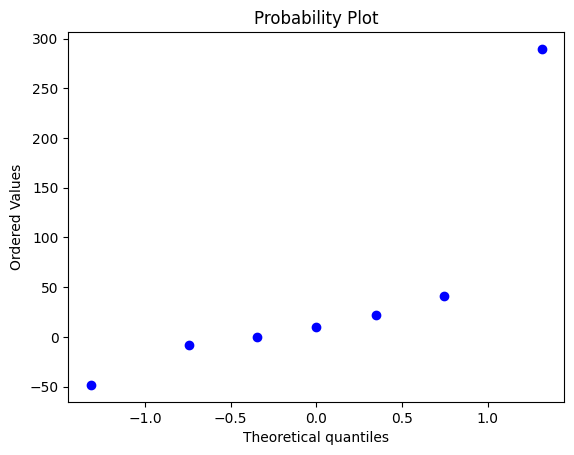

In [27]:
# ensure a 1D array
residual = np.asarray(resid).ravel()
# --- 1) Normal probability plot (MATLAB: normplot(resid)) ---
plt.figure()

if residual.size <= 1 or np.allclose(residual, residual[0]):
    # Degenerate case: not enough variation to fit a line
    # We can just scatter the points vs their normal quantiles.
    osmotic, ordered = stats.probplot(residual, dist="norm", fit=False)
    plt.plot(osmotic, ordered, "ok")
else:
    # Normal case: use probplot, but skip the regression line
    stats.probplot(residual, dist="norm", plot=plt, fit=False)

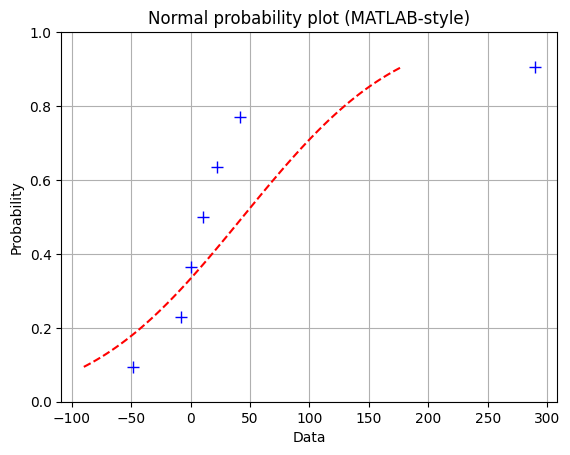

In [30]:
# residuals (1D array)
resid = np.asarray(resid).ravel()

# Getting quantiles and curve parameters
(osm, osr), (slope, intercept, r) = stats.probplot(resid, dist="norm", fit=True)

# Tranferring quantiles to probabilities (ось Y)
p = stats.norm.cdf(osm)

plt.figure()

# Plotting the dots
plt.plot(osr, p, "b+", markersize=8)

# Normal distribution line
z_line = np.linspace(osm.min(), osm.max(), 100)
p_line = stats.norm.cdf(z_line)
x_line = slope * z_line + intercept
plt.plot(x_line, p_line, "r--")

# Labels
plt.xlabel("Data")
plt.ylabel("Probability")
plt.ylim(0, 1)
plt.grid(True)

plt.title("Normal probability plot (MATLAB-style)")
plt.show()

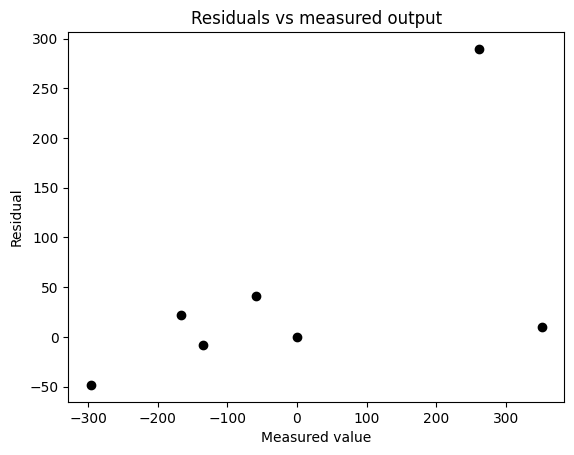

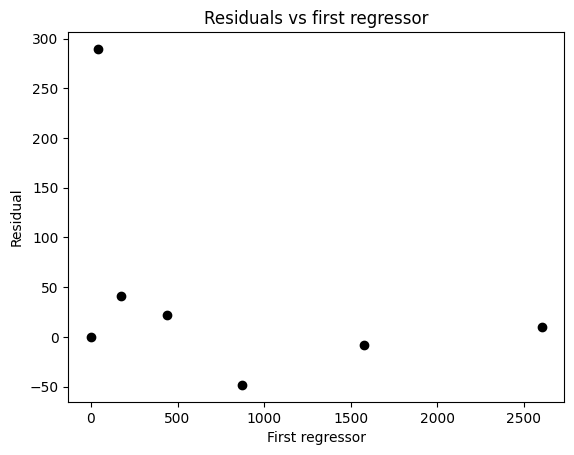

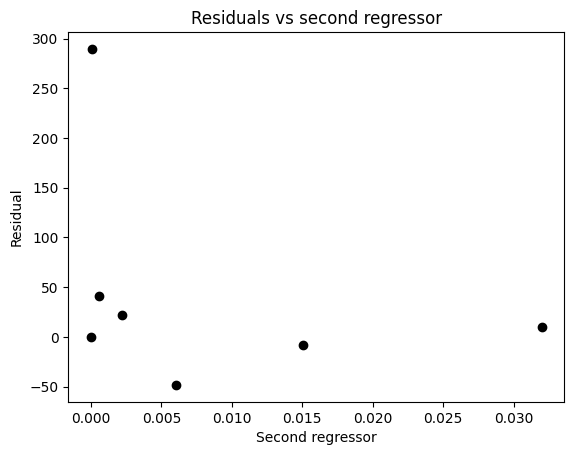

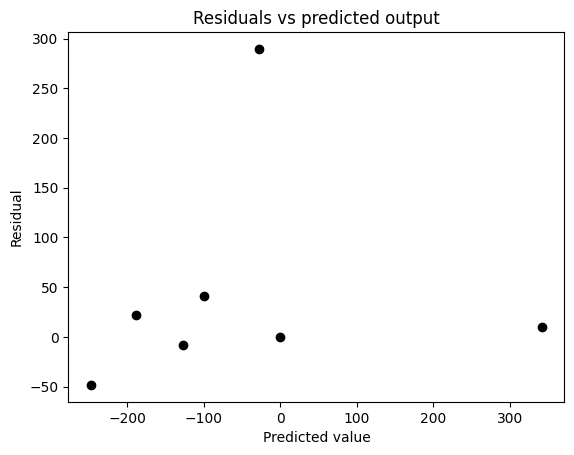

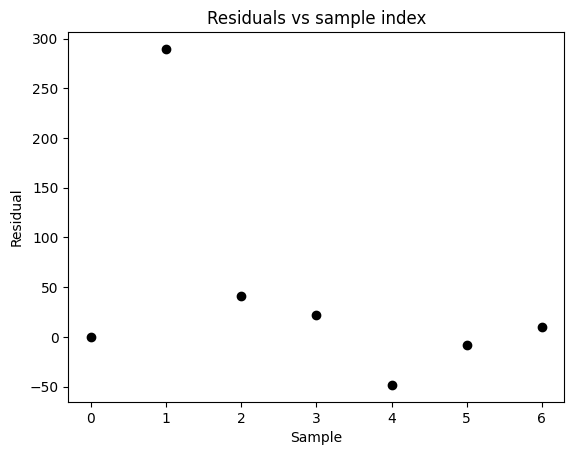

In [29]:
# --- 2) Residuals vs measured output y ---
plt.figure()
plt.plot(y, resid, "ok")
plt.xlabel("Measured value")
plt.ylabel("Residual")
plt.title("Residuals vs measured output")

# --- 3) Residuals vs first regressor A(:,1) ---
plt.figure()
plt.plot(A[:, 0], resid, "ok")   # column 1 in MATLAB is column 0 in Python
plt.xlabel("First regressor")
plt.ylabel("Residual")
plt.title("Residuals vs first regressor")

# --- 4) Residuals vs second regressor A(:,2) ---
plt.figure()
plt.plot(A[:, 1], resid, "ok")   # column 2 in MATLAB is column 1 in Python
plt.xlabel("Second regressor")
plt.ylabel("Residual")
plt.title("Residuals vs second regressor")

# --- 5) Residuals vs predicted output A*param ---
y_pred = A @ beta
plt.figure()
plt.plot(y_pred, resid, "ok")
plt.xlabel("Predicted value")
plt.ylabel("Residual")
plt.title("Residuals vs predicted output")

# --- 6) Residuals vs sample index (time-series plot) ---
plt.figure()
plt.plot(np.arange(len(resid)), resid, "ok")
plt.xlabel("Sample")
plt.ylabel("Residual")
plt.title("Residuals vs sample index")

plt.show()

In [32]:
# removing an outlier
mask = np.ones(len(y), dtype=bool)
mask[1] = False          # drop the second sample

y2 = y[mask]
A2 = A[mask, :]

print("y2:", y2)
print("A2 shape:", A2.shape)

y2: [[   0.]
 [ -59.]
 [-167.]
 [-296.]
 [-135.]
 [ 352.]]
A2 shape: (6, 2)


In [33]:
# refitting the regression
beta1, *_ = np.linalg.lstsq(A2, y2, rcond=None)

# Residuals for the new fit
resid2 = y2 - A2 @ beta1

# Basic dimensions
m2, n2 = A2.shape          # m2 = number of points (after removing outlier)
df2 = m2 - n2              # residual degrees of freedom
alpha = 0.05               # 95% confidence intervals


In [48]:
# Residual sum of squares and error variance
SSE2 = np.sum(resid2**2)
sigma2_hat = SSE2 / df2

# Covariance matrix of beta1
cov_beta = sigma2_hat * np.linalg.inv(A2.T @ A2)
se_beta = np.sqrt(np.diag(cov_beta))

# t critical value
tcrit = stats.t.ppf(1 - alpha/2, df2)

# 2×n matrix of CIs (rows: [lower, upper])
CI = np.vstack([beta1 - tcrit * se_beta,
                beta1 + tcrit * se_beta]).T

print(f"beta1(1) = {beta1[0].item():.4f}")
print(f"beta1(2) = {beta1[1].item():.4f}")

# confidence intervals (direct form)
print(f"CI(1,:) = [{CI[0,0]:.4f}, {CI[0,2]:.4f}]")
print(f"CI(2,:) = [{CI[1,1]:.4f}, {CI[1,3]:.4f}]")

beta1(1) = -0.8535
beta1(2) = 80344.4099
CI(1,:) = [-1.0216, -0.6855]
CI(2,:) = [65379.2464, 95309.5734]


In [35]:
# Predicted values
y2_hat = A2 @ beta1

# SSR, SSE, TSS for the new fit
SSR2 = np.sum((y2_hat - np.mean(y2))**2)
SSE2 = np.sum(resid2**2)
TSS2 = SSR2 + SSE2

R2_new = SSR2 / TSS2

k = n2                      # number of parameters (no intercept column)
F_new = (SSR2 / k) / (SSE2 / df2)

print(f"R^2 (new model) = {R2_new:.4f}")
print(f"F (new model)   = {F_new:.4f}")


R^2 (new model) = 0.9818
F (new model)   = 107.8485


In [49]:
# Critical F value for the new data
F_crit = stats.f.ppf(1 - alpha, dfn=k, dfd=m - n - 1) # one experiment has been removed
print(f"F_crit (alpha = {alpha}) = {F_crit:.4f}")

F_crit (alpha = 0.05) = 6.9443
